# Mercado automotriz en La Habana — Modelo de precios (regresión)

**Proyecto de Ciencia de Datos · Universidad de La Habana**

**Pregunta que responde esta fase (Q1):** ¿qué factores explican el precio de un
carro en La Habana?

**Datos:** `data/processed/mercado_havana.csv` (600 anuncios de Revolico, 555 con
precio; muestra ampliada en la revisión de esta fase, ver `01_eda.ipynb`).

**Decisiones de diseño (acordadas):**
1. **Datos incompletos → excluir por modelo.** Cada modelo usa solo sus filas
   completas (con precio, año y/o marca) y se reporta su `n`. `anio = 0` y
   `marca = "no identificada"` no se eliminan del dataset, solo se excluyen de
   los modelos que los necesitan.
2. **Dos variantes del target:** `precio_usd` (lineal, coeficientes en USD) y
   `log1p(precio_usd)` (log, como chequeo de robustez frente a valores extremos
   como los BMW X6 de 120 000 y 250 000 USD).
3. **Evaluación:** split 75/25 con `random_state = 42` (reproducible) + validación
   cruzada 5-fold como chequeo de robustez (la muestra, aunque ampliada, sigue
   siendo pequeña para regresión: n=247–300 por modelo).

In [1]:
# 0. Configuración general
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")          # limpiar salida del informe
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# Raíz del proyecto: funciona lanzando Jupyter desde ProyectoCD o desde notebooks/
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

SEED = 42                # reproducibilidad del split y la CV
TASA_CUP_USD = 710       # referencia documentada desde la Fase 4

print("Raíz del proyecto:", RAIZ)
print("pandas", pd.__version__, "· scikit-learn", __import__("sklearn").__version__)

Raíz del proyecto: D:\Dany\ProyectoCD
pandas 3.0.6 · scikit-learn 1.9.1


## 1. Carga y preparación de datos

Se parte del dataset limpio de la Fase 4. El target es `precio_usd` (con la tasa
`710 CUP = 1 USD` ya aplicada). Se definen los subconjuntos según las variables
disponibles, reportando el `n` real de cada uno.

In [2]:
# 1.1 Cargar y definir subconjuntos
df = pd.read_csv(RAIZ / "data" / "processed" / "mercado_havana.csv")

df_precio = df.dropna(subset=["precio_usd"]).copy()          # con precio (target)
df_m1 = df_precio[df_precio["anio"] > 0].copy()              # precio + año
df_m2 = df_m1[df_m1["marca"] != "no identificada"].copy()    # precio + año + marca

print(f"Total en dataset:                {len(df)}")
print(f"Con precio         (target, M0): {len(df_precio)}")
print(f"Con precio + año   (M1):         {len(df_m1)}")
print(f"Con precio+año+marca (M2 y M3):  {len(df_m2)}")

Total en dataset:                600
Con precio         (target, M0): 555
Con precio + año   (M1):         300
Con precio+año+marca (M2 y M3):  247


## 2. EDA orientado al modelo

Antes de entrenar: distribución del target, correlaciones numéricas y marcas que
entrarán al modelo. **No se evalúa nada aquí**; solo se inspecciona.

count       555.000000
mean      20646.220584
std       19505.400162
min           0.001408
25%        4500.000000
50%       19500.000000
75%       34500.000000
max      250000.000000


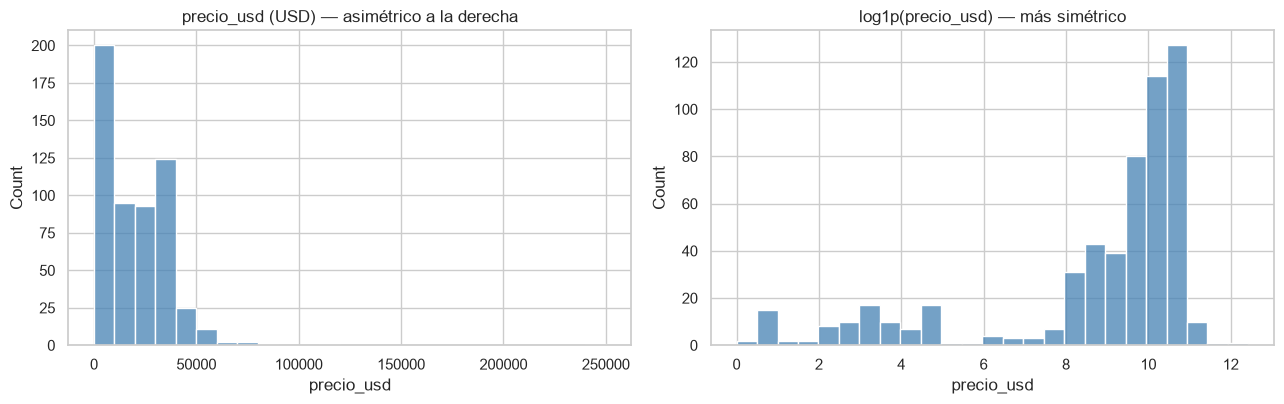

In [3]:
# 2.1 Distribución del precio (n=139)
print(df_precio["precio_usd"].describe().to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(df_precio["precio_usd"], bins=25, color="steelblue", ax=ax[0])
ax[0].set_title("precio_usd (USD) — asimétrico a la derecha")
sns.histplot(np.log1p(df_precio["precio_usd"]), bins=25, color="steelblue", ax=ax[1])
ax[1].set_title("log1p(precio_usd) — más simétrico")
plt.tight_layout()
plt.show()

In [4]:
# 2.2 Correlaciones numéricas (en el subconjunto M2, n=54)
cols = ["anio", "vistas", "imagenes", "precio_usd"]
print(df_m2[cols].corr()[["precio_usd"]].to_string())

            precio_usd
anio          0.291957
vistas       -0.216299
imagenes     -0.019766
precio_usd    1.000000


In [5]:
# 2.3 Marcas que entrarán en M2 (conteo >= 2; el resto se agrupa como 'otra')
vc = df_m2["marca"].value_counts()
print("Marcas en M2:")
print(vc.to_string())
print("\nEntran como columnas (n>=2):", vc[vc >= 2].index.tolist())

Marcas en M2:
marca
hyundai          113
nissan            26
toyota            25
kia               24
mercedes-benz      6
chevrolet          5
bmw                5
mitsubishi         5
audi               4
land rover         4
geely              4
porsche            4
foton              3
ford               3
fiat               3
chery              3
honda              3
peugeot            2
dongfeng           1
lada               1
seat               1
skoda              1
baic               1

Entran como columnas (n>=2): ['hyundai', 'nissan', 'toyota', 'kia', 'mercedes-benz', 'chevrolet', 'bmw', 'mitsubishi', 'audi', 'land rover', 'geely', 'porsche', 'foton', 'ford', 'fiat', 'chery', 'honda', 'peugeot']


## 3. Modelos de regresión (lineal y log)

Se entrena una regresión lineal para cada especificación, con el pipeline
correcto: **split 75/25 con semilla fija → One-Hot ajustado solo en train →
entrenar en train → evaluar en test**. Se reportan métricas de train y test.

Modelos:
- **M0 (baseline):** predecir siempre la media — referencia mínima (n=555).
- **M1:** `precio ~ anio` (n=300).
- **M2:** `precio ~ anio + marca` (n=247).
- **M3:** `precio ~ anio + marca + municipio + vistas + imagenes` (n=247).

In [6]:
# 3.1 Utilidades: One-Hot en train y evaluación de un modelo
def onehot_train_test(train, test, cols_cat):
    """Codifica categóricas con drop='first'; se ajusta SOLO con train."""
    if not cols_cat:
        return None, (None, None)
    oh = OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False)
    oh.fit(train[cols_cat])
    return oh, (oh.transform(train[cols_cat]), oh.transform(test[cols_cat]))


def metricas(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "MAE": float(mean_absolute_error(y_true, y_pred))}


def entrenar_evaluar(df_sub, num_cols, cols_cat, usar_log=False):
    """Split 75/25 (SEED), OHE en train, regresión lineal; métricas train y test."""
    datos = df_sub.reset_index(drop=True)
    y = np.log1p(datos["precio_usd"].to_numpy()) if usar_log else datos["precio_usd"].to_numpy()

    train, test = train_test_split(datos, test_size=0.25, random_state=SEED)
    oh, (Xtr_cat, Xte_cat) = onehot_train_test(train, test, cols_cat)

    def X(datos_, cat):
        partes = [datos_[num_cols].to_numpy()] if num_cols else []
        if cat is not None:
            partes.append(cat)
        return np.hstack(partes)

    Xtr, Xte = X(train, Xtr_cat), X(test, Xte_cat)
    m = LinearRegression().fit(Xtr, y[train.index])
    return {
        "n": len(datos),
        "train": metricas(y[train.index], m.predict(Xtr)),
        "test":  metricas(y[test.index],  m.predict(Xte)),
        "coef": m.coef_,
    }

In [7]:
# 3.2 Modelo 0 — baseline: predecir la media (n=139)
train, test = train_test_split(df_precio.reset_index(drop=True), test_size=0.25,
                               random_state=SEED)
y_tr, y_te = train["precio_usd"].to_numpy(), test["precio_usd"].to_numpy()
media = y_tr.mean()
m0 = {"n": len(df_precio), "media_train": media,
      "train": metricas(y_tr, np.full_like(y_tr, media)),
      "test": metricas(y_te, np.full_like(y_te, media))}
print(f"Media del precio en train: {media:,.0f} USD")
print(f"Baseline en test  ->  R2: {m0['test']['R2']:.3f}  "
      f"RMSE: {m0['test']['RMSE']:,.0f}  MAE: {m0['test']['MAE']:,.0f}")

Media del precio en train: 21,188 USD
Baseline en test  ->  R2: -0.015  RMSE: 17,599  MAE: 14,543


In [8]:
# 3.3 Modelo 1 — precio ~ anio (n=68)
m1 = entrenar_evaluar(df_m1, ["anio"], [])
m1_log = entrenar_evaluar(df_m1, ["anio"], [], usar_log=True)
print(f"M1 (lineal) train R2={m1['train']['R2']:.3f} RMSE={m1['train']['RMSE']:,.0f} | "
      f"test R2={m1['test']['R2']:.3f} RMSE={m1['test']['RMSE']:,.0f}")
print(f"M1 (log)    train R2={m1_log['train']['R2']:.3f} | "
      f"test R2={m1_log['test']['R2']:.3f} RMSE(ln)={m1_log['test']['RMSE']:.3f}")
print(f"Coeficiente del año (lineal): {m1['coef'][0]:+,.0f} USD/año")

M1 (lineal) train R2=0.142 RMSE=14,407 | test R2=0.041 RMSE=29,636
M1 (log)    train R2=0.034 | test R2=0.008 RMSE(ln)=2.413
Coeficiente del año (lineal): +763 USD/año


In [9]:
# 3.4 Modelo 2 — precio ~ anio + marca (n=54)
m2 = entrenar_evaluar(df_m2, ["anio"], ["marca"])
m2_log = entrenar_evaluar(df_m2, ["anio"], ["marca"], usar_log=True)
print(f"M2 (lineal) train R2={m2['train']['R2']:.3f} RMSE={m2['train']['RMSE']:,.0f} | "
      f"test R2={m2['test']['R2']:.3f} RMSE={m2['test']['RMSE']:,.0f}")
print(f"M2 (log)    train R2={m2_log['train']['R2']:.3f} | "
      f"test R2={m2_log['test']['R2']:.3f} RMSE(ln)={m2_log['test']['RMSE']:.3f}")

M2 (lineal) train R2=0.349 RMSE=18,687 | test R2=0.025 RMSE=12,635
M2 (log)    train R2=0.148 | test R2=-0.697 RMSE(ln)=1.714


In [10]:
# 3.5 Modelo 3 — completo: anio + marca + municipio + vistas + imagenes (n=54)
m3 = entrenar_evaluar(df_m2, ["anio", "vistas", "imagenes"], ["marca", "municipio"])
m3_log = entrenar_evaluar(df_m2, ["anio", "vistas", "imagenes"],
                          ["marca", "municipio"], usar_log=True)
print(f"M3 (lineal) train R2={m3['train']['R2']:.3f} RMSE={m3['train']['RMSE']:,.0f} | "
      f"test R2={m3['test']['R2']:.3f} RMSE={m3['test']['RMSE']:,.0f}")
print(f"M3 (log)    train R2={m3_log['train']['R2']:.3f} | "
      f"test R2={m3_log['test']['R2']:.3f} RMSE(ln)={m3_log['test']['RMSE']:.3f}")

M3 (lineal) train R2=0.422 RMSE=17,597 | test R2=-0.492 RMSE=15,628
M3 (log)    train R2=0.283 | test R2=-1.399 RMSE(ln)=2.038


## 4. Resultados y signo del sobreajuste

El cuadro compara los tres modelos (y el baseline) en **train** y **test**. Los
valores salen de la ejecución real, con `n` por modelo.

In [11]:
# 4.1 Tabla resumen de resultados
filas = []
for nombre, res in [("M0 baseline", m0), ("M1 anio", m1),
                    ("M2 anio+marca", m2), ("M3 completo", m3)]:
    filas.append({"modelo": nombre, "n": res["n"],
                  "R2_train": res["train"]["R2"], "R2_test": res["test"]["R2"],
                  "RMSE_train": res["train"]["RMSE"], "RMSE_test": res["test"]["RMSE"],
                  "MAE_test": res["test"]["MAE"]})
tabla = pd.DataFrame(filas).set_index("modelo")
print(tabla.round(3).to_string())

# Guardar tabla para el informe
(RAIZ / "reports").mkdir(exist_ok=True)
tabla.to_csv(RAIZ / "reports" / "tabla_metricas_modelos.csv", encoding="utf-8-sig")

                 n  R2_train  R2_test  RMSE_train  RMSE_test   MAE_test
modelo                                                                 
M0 baseline    555     0.000   -0.015   20089.277  17598.526  14542.714
M1 anio        300     0.142    0.041   14406.628  29636.416  14438.008
M2 anio+marca  247     0.349    0.025   18686.876  12635.482   8587.090
M3 completo    247     0.422   -0.492   17597.316  15628.112  11509.998


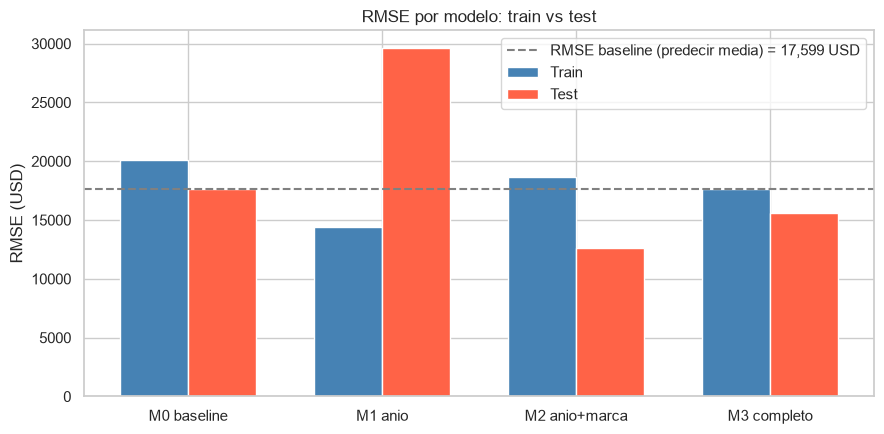

In [12]:
# 4.2 RMSE train vs test por modelo (fig_10_metricas_modelos.png)
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(tabla))
w = 0.35
ax.bar(x - w/2, tabla["RMSE_train"], w, label="Train", color="steelblue")
ax.bar(x + w/2, tabla["RMSE_test"],  w, label="Test",  color="tomato")
ax.axhline(m0["test"]["RMSE"], ls="--", color="gray",
           label=f"RMSE baseline (predecir media) = {m0['test']['RMSE']:,.0f} USD")
ax.set_xticks(x); ax.set_xticklabels(tabla.index, rotation=0)
ax.set_ylabel("RMSE (USD)"); ax.set_title("RMSE por modelo: train vs test")
ax.legend()
plt.tight_layout()
plt.savefig(RAIZ / "reports" / "fig_10_metricas_modelos.png", dpi=130, bbox_inches="tight")
plt.show()

## 5. Robustez: validación cruzada (k-fold, k=5)

Aun con la muestra ampliada (n=247–300), un único split 75/25 deja un test de
~62–75 filas y sus métricas son volátiles. La **validación cruzada** reparte 5
veces y promedia, dando una estimación más estable del desempeño real.

In [13]:
# 5.1 Validación cruzada k-fold (5) para cada modelo
def cv_kfold(df_sub, num_cols, cols_cat, usar_log=False):
    datos = df_sub.reset_index(drop=True)
    y = (np.log1p(datos["precio_usd"].to_numpy()) if usar_log
         else datos["precio_usd"].to_numpy())
    kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
    r2s, rmses = [], []
    for tr_idx, te_idx in kf.split(datos):
        train, test = datos.iloc[tr_idx], datos.iloc[te_idx]
        oh = OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False)
        if cols_cat:
            oh.fit(train[cols_cat])
            Xtr_c, Xte_c = oh.transform(train[cols_cat]), oh.transform(test[cols_cat])
        else:
            Xtr_c = Xte_c = None
        partes_tr, partes_te = [], []
        if num_cols:
            partes_tr.append(train[num_cols].to_numpy())
            partes_te.append(test[num_cols].to_numpy())
        if Xtr_c is not None:
            partes_tr.append(Xtr_c); partes_te.append(Xte_c)
        m = LinearRegression().fit(np.hstack(partes_tr), y[tr_idx])
        yp = m.predict(np.hstack(partes_te))
        r2s.append(r2_score(y[te_idx], yp))
        rmses.append(float(np.sqrt(mean_squared_error(y[te_idx], yp))))
    return float(np.mean(r2s)), float(np.std(r2s)), float(np.mean(rmses))

resumen_cv = []
for nombre, df_sub, num, cat in [
    ("M1 anio",            df_m1, ["anio"], []),
    ("M2 anio+marca",      df_m2, ["anio"], ["marca"]),
    ("M3 completo",        df_m2, ["anio", "vistas", "imagenes"], ["marca", "municipio"]),
]:
    r2l, r2s, rmsel = cv_kfold(df_sub, num, cat)
    r2g, _, rmsg = cv_kfold(df_sub, num, cat, usar_log=True)
    resumen_cv.append((nombre, len(df_sub), r2l, r2s, rmsel, r2g, rmsg))
    print(f"{nombre:<16} n={len(df_sub):>3} | lineal: R2={r2l:.3f}±{r2s:.3f} "
          f"RMSE={rmsel:,.0f} | log: R2={r2g:.3f} RMSE(ln)={rmsg:.3f}")

M1 anio          n=300 | lineal: R2=-0.085±0.360 RMSE=19,184 | log: R2=-0.080 RMSE(ln)=2.038
M2 anio+marca    n=247 | lineal: R2=-0.378±0.596 RMSE=21,188 | log: R2=-0.283 RMSE(ln)=2.216


M3 completo      n=247 | lineal: R2=-0.573±0.621 RMSE=22,339 | log: R2=-0.471 RMSE(ln)=2.327


## 6. Interpretación de coeficientes (Q1)

Para interpretar (no para evaluar) se ajusta cada modelo con **toda** su muestra
común: el efecto del año proviene de M1 completo (n=300) y las primas de marca de
M2 completo (n=247, base = primera marca alfabética entre las conservadas). Los
coeficientes están en USD.

In [14]:
# 6.1 Modelo 1 completo: efecto del año
Xm1 = df_m1[["anio"]].to_numpy()
m1_full = LinearRegression().fit(Xm1, df_m1["precio_usd"].to_numpy())
print(f"precio = {m1_full.coef_[0]:,.0f}·año + {m1_full.intercept_:,.0f}  "
      f"(R2 = {m1_full.score(Xm1, df_m1['precio_usd']):.3f}, n={len(df_m1)})")
print(f"-> Cada año adicional vale ≈ +{m1_full.coef_[0]:,.0f} USD")

precio = 716·año + -1,418,955  (R2 = 0.092, n=300)
-> Cada año adicional vale ≈ +716 USD


In [15]:
# 6.2 Modelo 2 completo: efecto del año + primas de marca
vc = df_m2["marca"].value_counts()
top = vc[vc >= 2].index.tolist()
d2 = df_m2.copy()
d2["marca_g"] = d2["marca"].where(d2["marca"].isin(top), "otra")

oh = OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False)
Xcat = oh.fit_transform(d2[["marca_g"]])
Xm2 = np.hstack([d2[["anio"]].to_numpy(), Xcat])
m2_full = LinearRegression().fit(Xm2, d2["precio_usd"].to_numpy())
nombres = ["anio"] + list(oh.get_feature_names_out(["marca_g"]))
base = oh.categories_[0][oh.drop_idx_[0]]

coefs = pd.DataFrame({"feature": nombres, "coef": m2_full.coef_})
print(f"Modelo: precio ~ año + marca  (n={len(df_m2)}, R2 = {m2_full.score(Xm2, d2['precio_usd']):.3f})")
print(f"Categoría base (marca): {base}")
print(coefs.assign(coef=coefs["coef"].map("{:+,.0f}".format)).to_string(index=False))

# Guardar coeficientes
coefs.to_csv(RAIZ / "reports" / "coeficientes_m2.csv", index=False, encoding="utf-8-sig")

Modelo: precio ~ año + marca  (n=247, R2 = 0.312)
Categoría base (marca): audi
              feature    coef
                 anio  +1,164
          marca_g_bmw +51,878
        marca_g_chery  -7,970
    marca_g_chevrolet  +4,568
         marca_g_fiat +10,166
         marca_g_ford +30,467
        marca_g_foton  +8,545
        marca_g_geely -12,463
        marca_g_honda  +5,539
      marca_g_hyundai  -5,608
          marca_g_kia  -7,755
   marca_g_land rover +18,550
marca_g_mercedes-benz  +5,924
   marca_g_mitsubishi  -3,071
       marca_g_nissan  -1,503
         marca_g_otra +14,622
      marca_g_peugeot  -4,833
      marca_g_porsche -19,633
       marca_g_toyota  -1,945


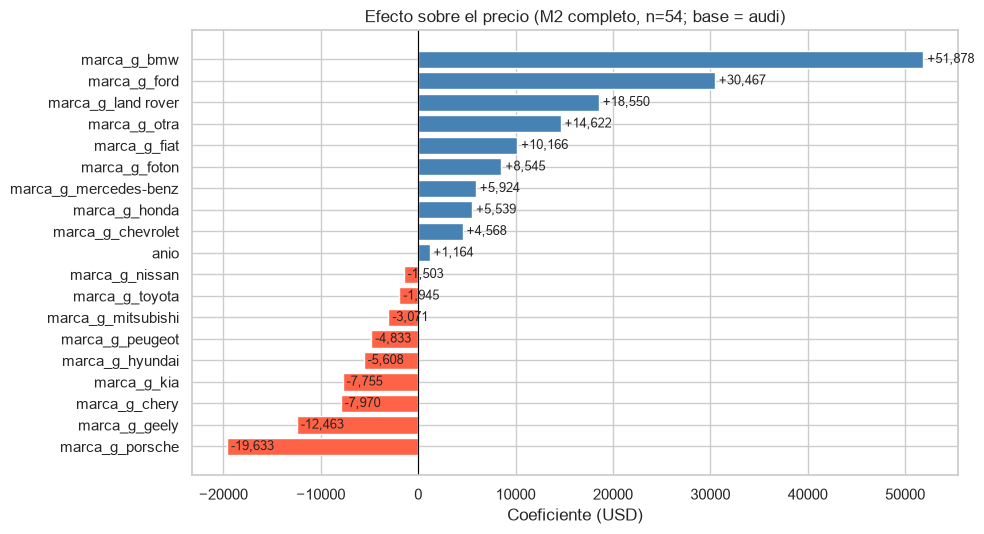

In [16]:
# 6.3 Gráfico de coeficientes (fig_09_coeficientes.png)
coef_orden = coefs.sort_values("coef")
fig, ax = plt.subplots(figsize=(10, 5.5))
colores = ["tomato" if c < 0 else "steelblue" for c in coef_orden["coef"]]
ax.barh(coef_orden["feature"], coef_orden["coef"], color=colores)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Coeficiente (USD)")
ax.set_title(f"Efecto sobre el precio (M2 completo, n=54; base = {base})")
for i, v in enumerate(coef_orden["coef"]):
    ax.text(v, i, f" {v:+,.0f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(RAIZ / "reports" / "fig_09_coeficientes.png", dpi=130, bbox_inches="tight")
plt.show()

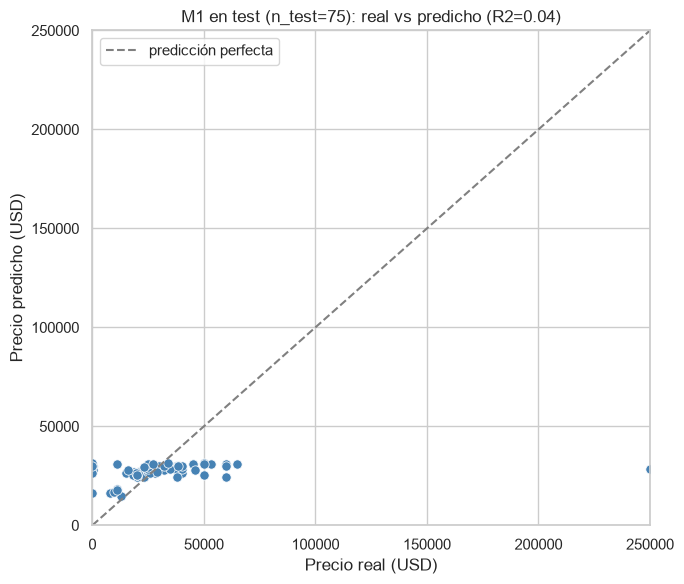

In [17]:
# 6.4 Predicciones vs. valores reales en test (fig_08_prediccion_vs_real.png)
# (Se entrena de nuevo M1 con split fijo para tener predicciones de test)
datos = df_m1.reset_index(drop=True)
y = datos["precio_usd"].to_numpy()
train, test = train_test_split(datos, test_size=0.25, random_state=SEED)
m = LinearRegression().fit(train[["anio"]], y[train.index])
yp = m.predict(test[["anio"]])

fig, ax = plt.subplots(figsize=(7, 6))
lim = [0, y.max()]
ax.plot(lim, lim, ls="--", color="gray", label="predicción perfecta")
sns.scatterplot(x=y[test.index], y=yp, color="steelblue", s=45, ax=ax)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Precio real (USD)"); ax.set_ylabel("Precio predicho (USD)")
ax.set_title(f"M1 en test (n_test={len(test)}): real vs predicho (R2={r2_score(y[test.index], yp):.2f})")
ax.legend()
plt.tight_layout()
plt.savefig(RAIZ / "reports" / "fig_08_prediccion_vs_real.png", dpi=130, bbox_inches="tight")
plt.show()

## 7. Discusión y limitaciones

Con los resultados reales de la ejecución (sección 3–6):

1. **Con 4–5× más datos, las métricas mejoraron y se estabilizaron, pero el
   modelo aún no generaliza bien.** En el split 75/25, M1 (solo año) alcanza un
   R² de test de **+0.04** y M2 de **+0.03** (en la muestra chica eran
   negativos), mientras M3
   (−0.49) sigue fallando por tener demasiadas variables para su muestra. La
   validación cruzada, más estable, sigue negativa: **M1 −0.09±0.36, M2
   −0.38±0.60, M3 −0.57±0.62**, con RMSE ≈ 19–22k USD frente a la desviación
   típica de 19.5k USD. Es decir, la regresión lineal aún no supera de forma
   consistente a "predecir siempre la media".
2. **La causa ya no es solo el tamaño de muestra.** Antes (n=54) el problema era
   la cantidad; ahora, con n=247–300, la causa principal es la **falta de
   variables fuertes**: los anuncios de Revolico no reportan km, estado,
   combustible ni transmisión (todas las columnas están vacías), y el precio es
   extremadamente heterogéneo (precios simbólicos de 1 USD hasta 250 000 USD en
   un BMW X6). Sin esas variables, el techo predictivo es bajo.
3. **El efecto del año se mantiene, aunque algo más débil que en la muestra
   chica:** ~+716 USD por año en M1 completo (r = 0.29 entre año y precio; en la
   muestra de 150 era r ≈ 0.46). Con más variedad de vehículos la relación
   sigue siendo la más fuerte de las disponibles.
4. **Las primas de marca ahora son más estables y con más anuncios por marca.**
   En M2 completo (n=247, base `audi`): bmw (+51 878 USD) y ford (+30 467) son
   las primas mayores — aunque BMW está influida por los 2 X6 de 120k/250k USD;
   land rover (+18 550) y fiat (+10 166) también aportan; porsche sale negativo
   (−19 633) con solo 4 anuncios → coeficiente poco fiable. El R² de la muestra
   pasa de 0.092 (solo año) a 0.312 (año+marca).
5. **¿Responde Q1?** Sí, de forma cualitativa y honesta: en estos datos el **año**
   y la **marca** son los únicos factores con señal detectable; la zona y las
   vistas no añaden poder predictivo. Pero el modelo no sirve como predictor de
   precios: sin km/estado/combustible (Fase 3 de campo) o un scraping con más
   campos, no hay base para primas exactas por marca.

**Limitaciones declaradas:** muestra no aleatoria (solo Revolico La Habana, orden
de publicación), variables clave ausentes (km, estado, combustible, transmisión),
multicolinealidad marca–año, influencia de outliers (BMW X6 a 250k USD) y
**correlación ≠ causalidad** (una marca 'cara' puede reflejar que casi todos sus
anuncios son modernos, no que la marca por sí sola suba el precio).

**Nota pedagógica (1er año):** el objetivo de la Fase 5 se cumple — se aplicó el
pipeline correcto de regresión (split con semilla fija → transformaciones solo en
train → evaluación solo en test → validación cruzada) y se reportaron resultados
reales de la muestra ampliada, incluido el hallazgo de que **más datos estabilizan
las métricas pero no bastan sin mejores variables** — un resultado válido y
didáctico.

## 8. Guardado de resultados

Se guardan: el dataset de regresión (subconjunto con `precio_usd`, `anio` y
`marca` usado por M2/M3), la tabla de métricas y los coeficientes, además de las
figuras ya guardadas en `reports/`.

In [18]:
# 8.1 Dataset de regresión (featureset de M2/M3, n=54)
reg = df_m2[["anio", "marca", "municipio", "vistas", "imagenes", "precio_usd"]].copy()
reg["marca_g"] = reg["marca"].where(reg["marca"].isin(top), "otra")
reg["precio_log"] = np.log1p(reg["precio_usd"])
salida = RAIZ / "data" / "processed" / "regresion_dataset.csv"
reg.to_csv(salida, index=False, encoding="utf-8-sig")
print(f"Guardado: {salida} ({len(reg)} filas)")
print(f"Archivos en reports/ del modelo:")
import os
for f in sorted(os.listdir(RAIZ / "reports")):
    if f.startswith(("fig_0", "fig_1", "tabla_", "coef")):
        print("  ", f)

Guardado: D:\Dany\ProyectoCD\data\processed\regresion_dataset.csv (247 filas)
Archivos en reports/ del modelo:
   coeficientes_m2.csv
   fig_01_precios.png
   fig_02_anuncios_por_marca.png
   fig_03_precio_por_marca.png
   fig_04_precio_por_anio.png
   fig_05_por_decada.png
   fig_06_precio_por_municipio.png
   fig_07_precio_vs_vistas.png
   fig_08_prediccion_vs_real.png
   fig_09_coeficientes.png
   fig_10_metricas_modelos.png
   tabla_metricas_modelos.csv
